In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Found 983 images belonging to 6 classes.
Found 250 images belonging to 6 classes.
Epoch 1/100


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


31/31 ━━━━━━━━━━━━━━━━━━━━ 370s 10s/step - accuracy: 0.4852 - loss: 1.3699 - val_accuracy: 0.7320 - val_loss: 0.7386
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 17s 447ms/step - accuracy: 0.7437 - loss: 0.7242 - val_accuracy: 0.8120 - val_loss: 0.5068
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 16s 389ms/step - accuracy: 0.7886 - loss: 0.6072 - val_accuracy: 0.8080 - val_loss: 0.5217
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 17s 453ms/step - accuracy: 0.7738 - loss: 0.5618 - val_accuracy: 0.8240 - val_loss: 0.4943
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 18s 455ms/step - accuracy: 0.8048 - loss: 0.5492 - val_accuracy: 0.8600 - val_loss: 0.4134
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 16s 391ms/step - accuracy: 0.8028 - loss: 0.4887 - val_accuracy: 0.8560 - val_loss: 0.4559
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 17s 455ms/step - accuracy: 0.8223 - loss: 0.4790 - val_accuracy: 0.8720 - val_loss: 0.3414
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 16s 394ms/step - accuracy: 0.8345 - loss: 0.4560 - val_accuracy:

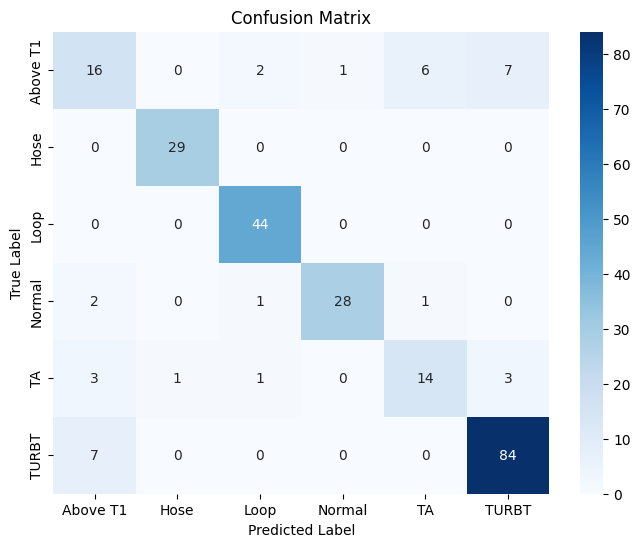

Classification Report
              precision    recall  f1-score   support

    Above T1       0.57      0.50      0.53        32
        Hose       0.97      1.00      0.98        29
        Loop       0.92      1.00      0.96        44
      Normal       0.97      0.88      0.92        32
          TA       0.67      0.64      0.65        22
       TURBT       0.89      0.92      0.91        91

    accuracy                           0.86       250
   macro avg       0.83      0.82      0.83       250
weighted avg       0.85      0.86      0.86       250



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# Importing required libraries
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Define paths to your dataset
train_dir = '/content/drive/MyDrive/BLC Dataset/WLI_split/train'
test_dir = '/content/drive/MyDrive/BLC Dataset/WLI_split/test'

# Define the image size and batch size
img_size = (224, 224)  # VGG16 requires 224x224 images
batch_size = 32

# Data augmentation and rescaling for training data
train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range=20,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

# Only rescaling for test data
test_datagen = ImageDataGenerator(rescale=1./255)

# Load the training and testing datasets
train_generator = train_datagen.flow_from_directory(train_dir,
                                                    target_size=img_size,
                                                    batch_size=batch_size,
                                                    class_mode='categorical')

test_generator = test_datagen.flow_from_directory(test_dir,
                                                  target_size=img_size,
                                                  batch_size=batch_size,
                                                  class_mode='categorical',
                                                  shuffle=False)

# Load the VGG16 model with ImageNet weights, exclude top layers
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the convolutional base to prevent updating pre-trained weights
for layer in base_model.layers:
    layer.trainable = False

# Adding custom layers for your 6 classes
x = Flatten()(base_model.output)
x = Dense(1024, activation='relu')(x)  # Adding a dense layer
x = Dense(512, activation='relu')(x)
predictions = Dense(6, activation='softmax')(x)  # 6 classes

# Combine base model and custom layers
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model and save the best weights
checkpoint_path = '/content/vgg16_best_weights.keras'  # Changed extension to .keras
checkpoint = tf.keras.callbacks.ModelCheckpoint(checkpoint_path, save_best_only=True, monitor='val_accuracy', mode='max')

history = model.fit(train_generator,
                    epochs=100,
                    validation_data=test_generator,
                    callbacks=[checkpoint])

# Evaluate the model on test data
test_loss, test_acc = model.evaluate(test_generator)
print(f'Test accuracy: {test_acc:.4f}')

# Predict on test data
Y_pred = model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)

# Confusion Matrix and Classification Report
class_labels = list(test_generator.class_indices.keys())

# Confusion matrix
cm = confusion_matrix(test_generator.classes, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Classification report
print('Classification Report')
report = classification_report(test_generator.classes, y_pred, target_names=class_labels)
print(report)

# Download the saved model weights
files.download(checkpoint_path)
